# Лабораторная работа № 5. Логистическая регрессия
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** изучение принципов построения информационных систем с использованием линейных методов машинного обучения.

**Задачи:** освоить линейную классификацию и разреженные матрицы; научиться обучать и оценивать логистическую регрессию; создавать признаки, масштабировать их и подбирать параметры.

## 1. Локальный запуск
Используем прежнее окружение Conda `rcaeval-ai` с Python 3.11 и scikit-learn 1.7.

Подключаем библиотеки.

In [1]:
from pathlib import Path
from importlib.metadata import version
from itertools import combinations
from urllib.request import urlopen
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error

from scipy.sparse import csr_matrix, hstack
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, RocCurveDisplay
from sklearn.model_selection import cross_validate

Задаём пути к данным и результатам.

In [2]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab05'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 17
sns.set_theme(style='whitegrid')

Выводим и сохраняем версии библиотек.

In [3]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn', 'scipy']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
numpy             2.2.6
pandas            2.3.3
matplotlib       3.10.9
seaborn          0.13.2
scikit-learn      1.7.2
scipy            1.17.1
Name: Версия, dtype: object

163

Определяем функцию сохранения и показа графиков.

In [4]:
def save_show(fig, name):
    fig.savefig(FIGURES / name, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Логистическая регрессия решает задачу **классификации**: выдаёт число от 0 до 1 для класса 1. При пороге 0,5 получаем ответ 0 или 1. ROC AUC оценивает, насколько хорошо модель ставит объекты класса 1 выше объектов класса 0 по этому числу. AUC = 0,5 соответствует случайному ранжированию, AUC = 1 — идеальному. Это не доля правильных ответов.

`C` задаёт обратную силу регуляризации: меньший C сильнее ограничивает веса. Подбираем его на данных для обучения и проверки, а не по итоговым отложенным строкам.

## 2. Учебная задача: сессии Alice
Определяем, принадлежит ли сессия Alice (1) или другому пользователю (0). Сессия содержит до десяти посещённых сайтов и время их посещения. Отсутствующий сайт означает, что в сессии было меньше десяти посещений.


### 2.1. Загрузка и просмотр

Загружаем учебные файлы только при отсутствии локальных копий.

In [5]:
ALICE = ROOT / 'data/raw/alice'
ALICE.mkdir(parents=True, exist_ok=True)
course_revision = '1a80eacf240821fd67525b0e0a44a20da9313f1f'
course_base = f'https://raw.githubusercontent.com/zikrach/mlcourse_open/{course_revision}/data/'
for local, remote in [('train_sessions.csv', 'websites_train_sessions.csv'),
                      ('test_sessions.csv', 'websites_test_sessions.csv'), ('site_dic.pkl', 'site_dic.pkl')]:
    path = ALICE / local
    if not path.exists():
        path.write_bytes(urlopen(course_base + remote, timeout=90).read())

Читаем таблицы и сортируем обучающие сессии по времени.

In [6]:
site_cols = [f'site{i}' for i in range(1, 11)]
time_cols = [f'time{i}' for i in range(1, 11)]
sessions = pd.read_csv(ALICE / 'train_sessions.csv', index_col='session_id', parse_dates=time_cols).sort_values('time1')
sessions_test = pd.read_csv(ALICE / 'test_sessions.csv', index_col='session_id', parse_dates=time_cols)

Печатаем первые строки и размеры таблиц.

In [7]:
display(sessions.head())
print('Обучающая таблица:', sessions.shape, '| Таблица без ответов:', sessions_test.shape)
display(sessions.target.value_counts().rename('Сессий'))

,site1,time1,site2,time2,site3,time3,site4,time4,site5,time5,...,time6,site7,time7,site8,time8,site9,time9,site10,time10,target
session_id,,,,,,,,,,,,,,,,,,,,,
21669,56,2013-01-12 08:05:57,55.0,2013-01-12 08:05:57,NaN,NaT,NaN,NaT,NaN,NaT,...,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,NaT,0
54843,56,2013-01-12 08:37:23,55.0,2013-01-12 08:37:23,56.0,2013-01-12 09:07:07,55.0,2013-01-12 09:07:09,NaN,NaT,...,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,NaT,0
77292,946,2013-01-12 08:50:13,946.0,2013-01-12 08:50:14,951.0,2013-01-12 08:50:15,946.0,2013-01-12 08:50:15,946.0,2013-01-12 08:50:16,...,2013-01-12 08:50:16,948.0,2013-01-12 08:50:16,784.0,2013-01-12 08:50:16,949.0,2013-01-12 08:50:17,946.0,2013-01-12 08:50:17,0
114021,945,2013-01-12 08:50:17,948.0,2013-01-12 08:50:17,949.0,2013-01-12 08:50:18,948.0,2013-01-12 08:50:18,945.0,2013-01-12 08:50:18,...,2013-01-12 08:50:18,947.0,2013-01-12 08:50:19,945.0,2013-01-12 08:50:19,946.0,2013-01-12 08:50:19,946.0,2013-01-12 08:50:20,0
146670,947,2013-01-12 08:50:20,950.0,2013-01-12 08:50:20,948.0,2013-01-12 08:50:20,947.0,2013-01-12 08:50:21,950.0,2013-01-12 08:50:21,...,2013-01-12 08:50:21,946.0,2013-01-12 08:50:21,951.0,2013-01-12 08:50:22,946.0,2013-01-12 08:50:22,947.0,2013-01-12 08:50:22,0


Обучающая таблица: (253561, 21) | Таблица без ответов: (82797, 20)


target
0    251264
1      2297
Name: Сессий, dtype: int64

Заменяем отсутствующие сайты нулём и читаем словарь сайтов.

In [8]:
sessions[site_cols] = sessions[site_cols].fillna(0).astype(int)
sessions_test[site_cols] = sessions_test[site_cols].fillna(0).astype(int)
site_dictionary = pd.read_pickle(ALICE / 'site_dic.pkl')
site_names = {identifier: name for name, identifier in site_dictionary.items()}
display(pd.Series(site_dictionary).head())

www.abmecatronique.com                25075
groups.live.com                       13997
majeureliguefootball.wordpress.com    42436
cdt46.media.tourinsoft.eu             30911
www.hdwallpapers.eu                    8104
dtype: int64

Находим десять самых посещаемых сайтов.

In [9]:
site_counts = pd.Series(sessions[site_cols].to_numpy().ravel()).value_counts().drop(0, errors='ignore').head(10)
display(pd.DataFrame({'Сайт': site_counts.index.map(site_names), 'Посещений': site_counts.to_numpy()}))

,Сайт,Посещений
0,www.google.fr,123776
1,www.google.com,87619
2,annotathon.org,77055
3,apis.google.com,58258
4,www.facebook.com,54094
5,www.bing.com,46405
6,blast.ncbi.nlm.nih.gov,43841
7,www.ncbi.nlm.nih.gov,38194
8,clients1.google.com,36085
9,mail.google.com,35178


Идентификатор сайта — обозначение, а не числовая величина: сайт 100 не «вдвое больше» сайта 50. Поэтому заменяем номера признаками, которые считают посещения каждого сайта. Повторные посещения в одной сессии учитываются.

Выделяем ответы и объединяем признаки обучающих и тестовых сессий.

In [10]:
y_alice = sessions.target.to_numpy()
all_sessions = pd.concat([sessions.drop(columns='target'), sessions_test])
n_train = len(sessions)
cut = int(0.9 * n_train)
print('Первые 90% для обучения:', cut, '| Последние 10% для проверки:', n_train - cut)

Первые 90% для обучения: 228204 | Последние 10% для проверки: 25357


Объединение используется только для одинакового формирования счётчиков и временных признаков. Целевые ответы не входят в объединённую таблицу. Средние и разброс для масштабирования далее считаем только по обучающим 90%. Проверочная часть расположена позже по времени.

Создаём разреженную матрицу посещений сайтов.

In [11]:
site_ids = all_sessions[site_cols].to_numpy().ravel()
row_ids = np.repeat(np.arange(len(all_sessions)), 10)
site_matrix = csr_matrix((np.ones(len(site_ids)), (row_ids, site_ids)),
                         shape=(len(all_sessions), max(site_dictionary.values()) + 1))[:, 1:]
print('Размер:', site_matrix.shape, '| Ненулевых элементов:', site_matrix.nnz)
print('Разреженная матрица, МБ:', (site_matrix.data.nbytes + site_matrix.indices.nbytes + site_matrix.indptr.nbytes) / 1e6)
print('Та же плотная матрица float64, ГБ:', np.prod(site_matrix.shape) * 8 / 1e9)

Размер: (336358, 48371) | Ненулевых элементов: 1866898
Разреженная матрица, МБ: 23.748212
Та же плотная матрица float64, ГБ: 130.159782544


Один столбец соответствует сайту, одно значение - числу его посещений в сессии. Нулевая колонка-заглушка удалена. Большинство сайтов в отдельной сессии не встречается. Разреженная матрица хранит только ненулевые элементы и их позиции.

### 2.2. Время сессии и синтезированные признаки

Определяем начало, конец и длительность сессий.

In [12]:
session_times = pd.DataFrame(index=all_sessions.index)
session_times['start'] = all_sessions[time_cols].min(axis=1)
session_times['end'] = all_sessions[time_cols].max(axis=1)
session_times['duration'] = (session_times.end - session_times.start).dt.total_seconds()
display(session_times.head())

,start,end,duration
session_id,,,
21669,2013-01-12 08:05:57,2013-01-12 08:05:57,0.0
54843,2013-01-12 08:37:23,2013-01-12 09:07:09,1786.0
77292,2013-01-12 08:50:13,2013-01-12 08:50:17,4.0
114021,2013-01-12 08:50:17,2013-01-12 08:50:20,3.0
146670,2013-01-12 08:50:20,2013-01-12 08:50:22,2.0


Создаём месяц, число уникальных сайтов, час и признак утра.

In [13]:
new_features = pd.DataFrame(index=all_sessions.index)
new_features['start_month'] = session_times.start.dt.year * 100 + session_times.start.dt.month
new_features['n_unique_sites'] = site_matrix.getnnz(axis=1)
new_features['start_hour'] = session_times.start.dt.hour
new_features['morning'] = (new_features.start_hour <= 11).astype(int)
display(new_features.head())

,start_month,n_unique_sites,start_hour,morning
session_id,,,,
21669,201301,2,8,1
54843,201301,2,8,1
77292,201301,6,8,1
114021,201301,5,8,1
146670,201301,6,8,1


`start_month` хранит число вида ГГГГММ, как в методичке. Это грубое числовое представление месяца: переход между декабрём и январём не равен одному шагу. `morning` равно 1 до 12 часов. `n_unique_sites` считает разные сайты, а не все посещения.

Определяем функцию добавления временных признаков к разреженной матрице.

In [14]:
def alice_matrix(columns, scaled, fit_rows=cut):
    if not columns:
        return site_matrix
    extra = new_features[columns].to_numpy(dtype=float)
    if scaled:
        scaler = StandardScaler().fit(extra[:fit_rows])
        extra = scaler.transform(extra)
    return hstack([site_matrix, csr_matrix(extra)], format='csr')

Определяем функцию проверки модели на последних 10% обучающей таблицы.

In [15]:
def alice_quality(columns, scaled=True, C=1.0):
    matrix = alice_matrix(columns, scaled)
    model = LogisticRegression(C=C, solver='liblinear', max_iter=1000, random_state=SEED)
    model.fit(matrix[:cut], y_alice[:cut])
    probabilities = model.predict_proba(matrix[cut:n_train])[:, 1]
    return roc_auc_score(y_alice[cut:], probabilities)

### 2.3. Базовая модель и добавление признаков

Сравниваем базовую модель и варианты новых признаков.

In [16]:
alice_variants = [
    ('Только сайты', [], False),
    ('Сайты и месяц без масштаба', ['start_month'], False),
    ('Сайты и месяц с масштабом', ['start_month'], True),
    ('Месяц и уникальные сайты', ['start_month', 'n_unique_sites'], True),
    ('Месяц, час, утро', ['start_month', 'start_hour', 'morning'], True),
    ('Все четыре новых признака', list(new_features.columns), True)
]
alice_comparison = pd.DataFrame([{'Вариант': name, 'AUC': alice_quality(cols, scaled)}
                                 for name, cols, scaled in alice_variants])
display(alice_comparison)

,Вариант,AUC
0,Только сайты,0.919527
1,Сайты и месяц без масштаба,0.750846
2,Сайты и месяц с масштабом,0.919690
3,Месяц и уникальные сайты,0.916140
4,"Месяц, час, утро",0.959151
5,Все четыре новых признака,0.955913


Строим график качества после добавления признаков.

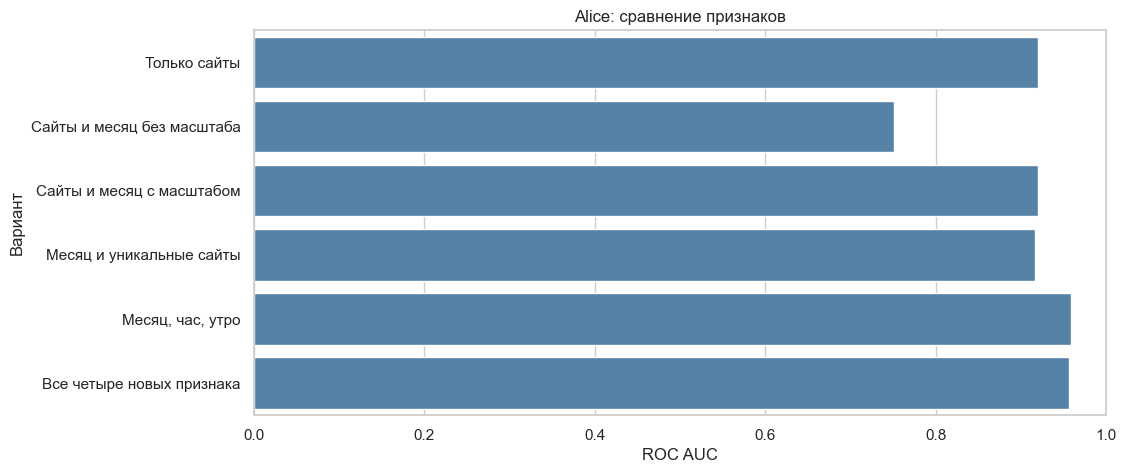

In [17]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=alice_comparison, x='AUC', y='Вариант', color='steelblue', ax=ax)
ax.set(title='Alice: сравнение признаков', xlim=(0, 1), xlabel='ROC AUC')
save_show(fig, '01_alice_features.png')

Длинная полоса означает более высокую AUC на одних и тех же проверочных сессиях. Масштабирование месяца сравнивается отдельно. Добавление признака не обязано улучшать результат: оцениваем это по полученным числам. Эта часть служит подбором, а не независимой итоговой оценкой.

Обучаем базовую модель на всех известных ответах и сохраняем baseline.

In [18]:
alice_baseline = LogisticRegression(C=1, solver='liblinear', max_iter=1000, random_state=SEED).fit(
    site_matrix[:n_train], y_alice)
pd.DataFrame({'target': alice_baseline.predict_proba(site_matrix[n_train:])[:, 1]},
             index=sessions_test.index).to_csv(REPORT / 'alice_baseline_sites.csv', index_label='session_id')

### 2.4. Подбор C и сохранение окончательного прогноза

Выбираем набор признаков по проверочной AUC и сравниваем десять значений C.

In [19]:
best_variant = int(alice_comparison.AUC.idxmax())
alice_columns = alice_variants[best_variant][1]
alice_scaled = alice_variants[best_variant][2]
C_values = np.logspace(-3, 1, 10)
alice_C = pd.DataFrame({'C': C_values,
                        'AUC': [alice_quality(alice_columns, alice_scaled, C) for C in C_values]})
display(alice_C)

,C,AUC
0,0.001000,0.816986
1,0.002783,0.895492
2,0.007743,0.938901
3,0.021544,0.956399
4,0.059948,0.960701
5,0.166810,0.961216
6,0.464159,0.960325
7,1.291550,0.958668
8,3.593814,0.955767
9,10.000000,0.951333


Строим график AUC в зависимости от C.

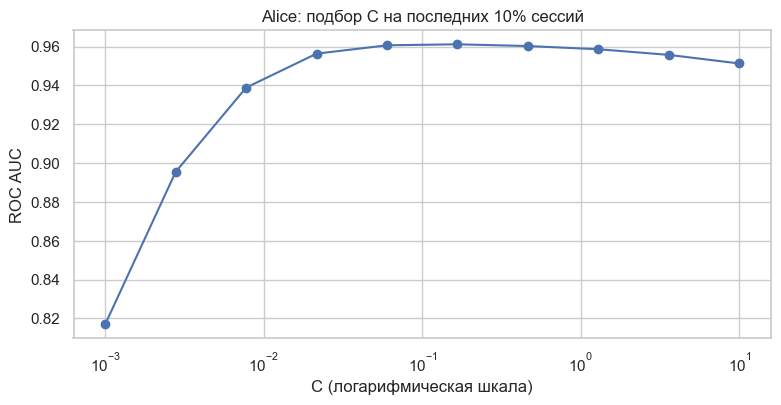

In [20]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogx(alice_C.C, alice_C.AUC, marker='o')
ax.set(title='Alice: подбор C на последних 10% сессий', xlabel='C (логарифмическая шкала)', ylabel='ROC AUC')
save_show(fig, '02_alice_C.png')

Выбираем точку с наибольшей AUC. Горизонтальная ось логарифмическая: соседние точки отличаются в несколько раз. Маленький C сильнее ограничивает веса, большой C даёт модели больше свободы. Число из примера методички не задаём заранее: используем свой расчёт.

Обучаем выбранный вариант на всей обучающей таблице и сохраняем прогноз.

In [21]:
alice_best_C = float(alice_C.loc[alice_C.AUC.idxmax(), 'C'])
alice_final_matrix = alice_matrix(alice_columns, alice_scaled, fit_rows=n_train)
alice_final = LogisticRegression(C=alice_best_C, solver='liblinear', max_iter=1000, random_state=SEED).fit(
    alice_final_matrix[:n_train], y_alice)
alice_test_probability = alice_final.predict_proba(alice_final_matrix[n_train:])[:, 1]
pd.DataFrame({'target': alice_test_probability}, index=sessions_test.index).to_csv(
    REPORT / 'alice_baseline_final.csv', index_label='session_id')
print('Выбранный вариант:', alice_variants[best_variant][0], '| C:', alice_best_C)
print('Сохранено ответов:', len(alice_test_probability))

Выбранный вариант: Месяц, час, утро | C: 0.1668100537200059
Сохранено ответов: 82797


## 3. Индивидуальное задание: RCAEval
### 3.1. Данные и исходная модель

Каждая строка - измерение в один момент времени. Класс 0 означает период до внесения сбоя, класс 1 - начиная с внесения. Модель определяет период по четырём метрикам `checkoutservice`. Время и метка периода не входят в признаки. Метка «после» не является отдельной проверкой неисправности каждой строки.

Это прежний CPU-сценарий RCAEval RE2-OB (Online Boutique). Из одного сценария нельзя оценить обнаружение всех видов сбоев.

Читаем имя прежнего сценария.

In [22]:
selection = json.loads((ROOT / 'reports/lab01/selected_case.json').read_text(encoding='utf-8'))
case = selection['case']
case_dir = ROOT / 'data/raw/rcaeval' / case

Загружаем сохранённые метрики и время внесения сбоя.

In [23]:
metrics_path = case_dir / 'metrics.parquet'
inject_path = case_dir / 'inject_time.txt'
df = pd.read_parquet(metrics_path)
inject_time = int(inject_path.read_text(encoding='utf-8').strip())

Печатаем первые строки и сведения о данных.

In [24]:
display(df.head())
print('Сценарий:', case, '| Сервис:', selection['root_cause_service'], '| Сбой:', selection['fault'])
print('Строк:', len(df), '| Метрик:', df.shape[1] - 1)
print('Момент внесения:', pd.to_datetime(inject_time, unit='s', utc=True))

,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,paymentservice_cpu,productcatalogservice_cpu,recommendationservice_cpu,...,adservice_latency-90,cartservice_latency-90,checkoutservice_latency-90,currencyservice_latency-90,emailservice_latency-90,frontend_latency-90,paymentservice_latency-90,productcatalogservice_latency-90,recommendationservice_latency-90,shippingservice_latency-90
0,1705353846,0.685023,2.216467,0.215886,19.035876,0.279166,6.724489,0.52931,2.636831,2.474853,...,0.004604,0.004993,0.850000,0.110638,0.0046,0.819737,0.008955,0.004418,0.009670,0.004576
1,1705353847,0.685023,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.636858,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008955,0.004423,0.009672,0.004576
2,1705353848,0.582707,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.584059,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008636,0.004423,0.009672,0.004576
3,1705353849,0.625903,2.216467,0.380058,19.106596,0.279166,6.724489,0.52931,3.250317,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576
4,1705353850,0.613414,2.216467,0.380058,19.106596,0.279166,5.572668,0.52931,3.250317,2.474853,...,0.004594,0.006304,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576


Сценарий: re2ob_checkoutservice_cpu_1 | Сервис: checkoutservice | Сбой: cpu
Строк: 1441 | Метрик: 72
Момент внесения: 2024-01-15 21:36:06+00:00


Выбираем признаки и формируем классы.

In [25]:
rca_features = ['checkoutservice_cpu', 'checkoutservice_mem',
                'checkoutservice_latency-50', 'checkoutservice_socket']
X = df[rca_features].copy()
y = (df['time'] >= inject_time).astype(int)
class_names = ['До внесения', 'После внесения']

Показываем назначение признаков, пропуски и число строк каждого класса.

In [26]:
display(pd.DataFrame({'Признак': rca_features,
                      'Описание': ['CPU', 'Память', 'Медианная задержка', 'Показатель socket'],
                      'Тип': X.dtypes.to_numpy(), 'Пропуски': X.isna().sum().to_numpy()}))
display(y.value_counts().sort_index().rename(index=dict(enumerate(class_names))).rename('Строк'))

,Признак,Описание,Тип,Пропуски
0,checkoutservice_cpu,CPU,float64,0
1,checkoutservice_mem,Память,float64,0
2,checkoutservice_latency-50,Медианная задержка,float64,0
3,checkoutservice_socket,Показатель socket,float64,0


time
До внесения       720
После внесения    721
Name: Строк, dtype: int64

В выбранных четырёх числовых признаках нет пропусков. Исходные значения не изменяем. Точные единицы отдельных метрик в локальном файле не указаны, поэтому сохраняем исходную шкалу.

Оставляем целые минутные участки для итоговой проверки.

In [27]:
groups = ((df['time'] - df['time'].min()) // 60).astype(int)
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(outer_cv.split(X, y, groups))
X_dev, X_test = X.iloc[dev_idx], X.iloc[test_idx]
y_dev, y_test = y.iloc[dev_idx], y.iloc[test_idx]
groups_dev = groups.iloc[dev_idx]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
print('Для подбора:', len(X_dev), '| Для итоговой проверки:', len(X_test))

Для подбора: 1141 | Для итоговой проверки: 300


Соседние по времени измерения похожи. Поэтому при CV и итоговой проверке записи одной минуты остаются вместе. Все параметры подбираем на `X_dev`. Отложенные `X_test` используем после выбора. Это проверка в рамках одного эксперимента, не прогноз будущего или проверка на новом сбое.

Определяем функцию создания логистической модели с масштабированием и без него.

In [28]:
def logistic_model(C=1.0, scaled=True):
    model = LogisticRegression(C=C, solver='liblinear', max_iter=1000, random_state=SEED)
    return make_pipeline(StandardScaler(), model) if scaled else model

### 3.2. Два новых признака и сравнение масштабирования — пункт 2.1
Создаём произведение CPU и памяти, выраженной в миллионах исходных единиц, а также квадрат CPU. Эти признаки вычисляются из исходных метрик; ответы и время в них не используются. Число новых признаков — ровно два.

Создаём два синтезированных признака.

In [29]:
X_extended = X.copy()
X_extended['cpu_mem'] = X.checkoutservice_cpu * (X.checkoutservice_mem / 1e6)
X_extended['cpu_squared'] = X.checkoutservice_cpu ** 2
Xe_dev = X_extended.iloc[dev_idx]
Xe_test = X_extended.iloc[test_idx]
display(X_extended.head())

,checkoutservice_cpu,checkoutservice_mem,checkoutservice_latency-50,checkoutservice_socket,cpu_mem,cpu_squared
0,0.215886,11702272.0,0.243182,9.0,2.526362,0.046607
1,0.380058,11706368.0,0.299999,9.0,4.449099,0.144444
2,0.380058,11706368.0,0.299999,9.0,4.449099,0.144444
3,0.380058,11706368.0,0.299999,9.0,4.449099,0.144444
4,0.380058,11706368.0,0.299999,9.0,4.449099,0.144444


Сравниваем четыре варианта по одной и той же CV.

In [30]:
variants = [('Исходные без масштаба', X_dev, False), ('Исходные с масштабом', X_dev, True),
            ('Два новых без масштаба', Xe_dev, False), ('Два новых с масштабом', Xe_dev, True)]
comparison_rows = []
for name, features, scaled in variants:
    scores = cross_validate(logistic_model(scaled=scaled), features, y_dev,
                            groups=groups_dev, cv=cv, scoring={'AUC': 'roc_auc', 'accuracy': 'accuracy'})
    comparison_rows.append({'Вариант': name, 'AUC': scores['test_AUC'].mean(),
                            'accuracy': scores['test_accuracy'].mean(), 'std': scores['test_AUC'].std()})
comparison = pd.DataFrame(comparison_rows)
display(comparison)

,Вариант,AUC,accuracy,std
0,Исходные без масштаба,0.997407,0.517403,0.005185
1,Исходные с масштабом,0.997407,0.988333,0.005185
2,Два новых без масштаба,0.988259,0.826570,0.023481
3,Два новых с масштабом,0.997407,0.988333,0.005185


Строим график влияния новых признаков и масштаба.

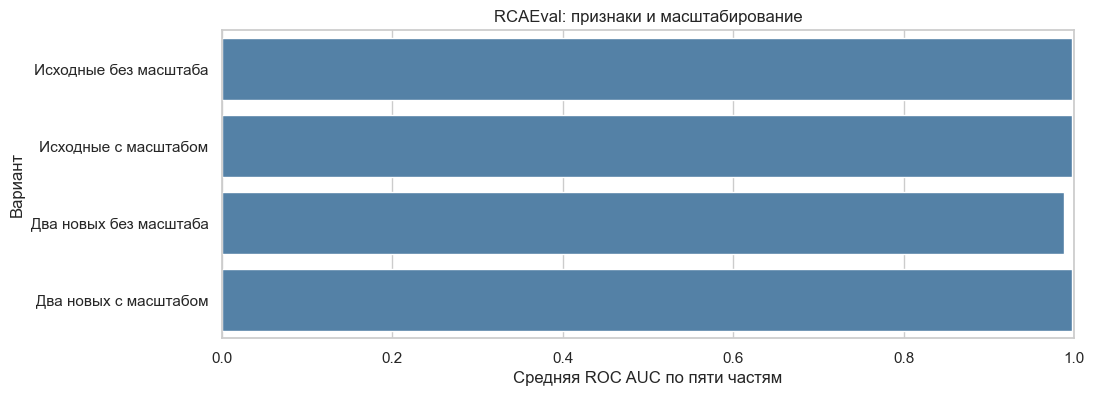

In [31]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=comparison, x='AUC', y='Вариант', color='steelblue', ax=ax)
ax.set(title='RCAEval: признаки и масштабирование', xlabel='Средняя ROC AUC по пяти частям', xlim=(0, 1))
save_show(fig, '03_rca_features.png')

Сравниваем исходные и расширенные признаки при одинаковом способе подготовки. `AUC` оценивает порядок оценок класса 1, `accuracy` долю верных ответов при пороге 0,5, `std` разброс AUC между частями. Высокая AUC не гарантирует хороших ответов при выбранном пороге.

Выбираем наибольшую AUC, при равенстве - большую accuracy по тем же частям CV. Если обе оценки равны, предпочитаем масштабирование и исходный набор признаков. Порядок `[1, 3, 0, 2]` в коде задаёт это последнее правило. Итоговая проверка в выборе не участвует.

В полученной таблице исходные признаки без масштаба и с ним дали одинаковую AUC около 0,997. Но accuracy без масштаба составила около 52%, а с ним около 99%. Поэтому для ответов при пороге 0,5 масштабирование здесь полезно. Два новых признака после масштабирования не улучшили эти оценки.

### 3.3. Выбор C

Выбираем вариант и перебираем C по пяти частям CV.

In [32]:
preferred_order = [1, 3, 0, 2]
best_variant_rca = max(preferred_order, key=lambda i: (comparison.AUC.iloc[i], comparison.accuracy.iloc[i]))
variant_name, selected_dev, selected_scaled = variants[best_variant_rca]
selected_test = X_test if best_variant_rca < 2 else Xe_test
C_rows = []
for C in C_values:
    scores = cross_validate(logistic_model(C, selected_scaled), selected_dev, y_dev,
                            groups=groups_dev, cv=cv, scoring={'AUC': 'roc_auc', 'accuracy': 'accuracy'})
    C_rows.append({'C': C, 'AUC': scores['test_AUC'].mean(),
                   'accuracy': scores['test_accuracy'].mean(), 'std': scores['test_AUC'].std()})
C_table = pd.DataFrame(C_rows)
display(C_table)

,C,AUC,accuracy,std
0,0.001000,0.997407,0.988333,0.005185
1,0.002783,0.997407,0.988333,0.005185
2,0.007743,0.997407,0.988333,0.005185
3,0.021544,0.997407,0.988333,0.005185
4,0.059948,0.997407,0.988333,0.005185
5,0.166810,0.997407,0.988333,0.005185
6,0.464159,0.997407,0.988333,0.005185
7,1.291550,0.997407,0.988333,0.005185
8,3.593814,0.997407,0.987500,0.005185
9,10.000000,0.997407,0.987500,0.005185


Строим зависимость ROC AUC от C для RCAEval.

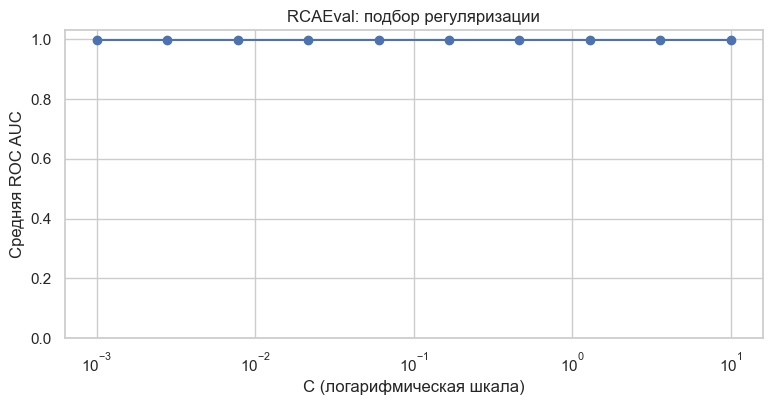

In [33]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogx(C_table.C, C_table.AUC, marker='o')
ax.set(title='RCAEval: подбор регуляризации', xlabel='C (логарифмическая шкала)', ylabel='Средняя ROC AUC', ylim=(0, 1.03))
save_show(fig, '04_rca_C.png')

Выбираем наибольшую среднюю AUC. При равенстве сравниваем accuracy по тем же частям CV; если и она равна, берём меньшее C. Такая модель сильнее ограничивает веса. Плоская линия AUC означает, что этот показатель не различает несколько C, поэтому в таблице также приведена accuracy.

Обучаем выбранную модель и проверяем на отложенных минутах.

In [34]:
best_C = float(C_table.sort_values(['AUC', 'accuracy', 'C'], ascending=[False, False, True]).iloc[0].C)
final_model = logistic_model(best_C, selected_scaled).fit(selected_dev, y_dev)
probability = final_model.predict_proba(selected_test)[:, 1]
prediction = (probability >= 0.5).astype(int)
final_auc = roc_auc_score(y_test, probability)
final_accuracy = accuracy_score(y_test, prediction)
print('Выбранный набор:', variant_name, '| C:', best_C)
print(f'Итоговая ROC AUC: {final_auc:.3f}; accuracy при пороге 0,5: {final_accuracy:.3f}')

Выбранный набор: Исходные с масштабом | C: 0.001
Итоговая ROC AUC: 1.000; accuracy при пороге 0,5: 1.000


Строим ROC-кривую выбранной модели.

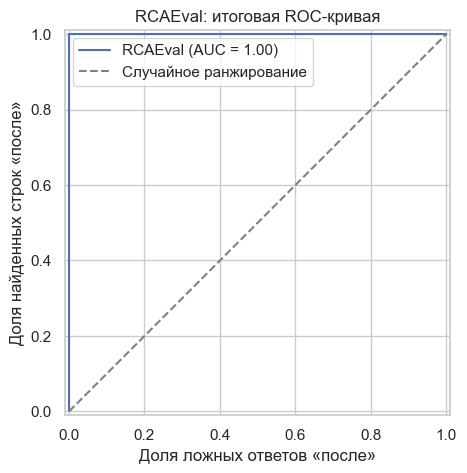

In [35]:
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, probability, name='RCAEval', ax=ax)
ax.plot([0, 1], [0, 1], '--', color='gray', label='Случайное ранжирование')
ax.set(title='RCAEval: итоговая ROC-кривая', xlabel='Доля ложных ответов «после»',
       ylabel='Доля найденных строк «после»')
ax.legend()
save_show(fig, '05_rca_roc.png')

Кривая показывает разные пороги решения. Чем ближе она к левому верхнему углу, тем лучше модель отделяет периоды на этой подвыборке. Пунктир ориентир случайного ранжирования. AUC оценивает всю кривую, accuracy выше рассчитана только при пороге 0,5.

### 3.4. Сохранение результатов

Сохраняем ответы исходной и выбранной моделей на отложенных строках.

In [36]:
base_model = logistic_model().fit(X_dev, y_dev)
baseline_probability = base_model.predict_proba(X_test)[:, 1]
pd.DataFrame({'row': X_test.index, 'time': df.loc[X_test.index, 'time'].to_numpy(),
              'actual': y_test.to_numpy(), 'probability': baseline_probability,
              'prediction': (baseline_probability >= 0.5).astype(int)}).to_csv(REPORT / 'rca_baseline.csv', index=False)
pd.DataFrame({'row': selected_test.index, 'actual': y_test.to_numpy(), 'probability': probability,
              'prediction': prediction}).to_csv(REPORT / 'rca_selected_predictions.csv', index=False)
print('Сохранены rca_baseline.csv и rca_selected_predictions.csv')

Сохранены rca_baseline.csv и rca_selected_predictions.csv


Baseline — начальный результат, с которым можно сравнить улучшения. Здесь это исходные четыре признака, масштабирование и C = 1. Файл содержит настоящие периоды, оценки класса 1 и ответы по порогу 0,5. Исходный датасет не перезаписывается.

Составляем простой текст результата и сохраняем таблицы.

In [37]:
analysis = (f'Изучил логистическую регрессию на сессиях Alice и сценарии {case}. '
            'Создал два новых признака RCAEval и сравнил модели с масштабированием и без него. '
            f'Выбран вариант «{variant_name}», C = {best_C:.4g}. '
            f'На отложенных строках ROC AUC = {final_auc:.3f}; верных ответов при пороге 0,5 — {final_accuracy:.1%}. '
            'Сохранил исходный baseline и прогноз выбранной модели. Результат относится к одному CPU-эксперименту.')
display(Markdown(analysis))
(REPORT / 'analysis.md').write_text(analysis, encoding='utf-8')
comparison.to_csv(REPORT / 'rca_feature_comparison.csv', index=False)
C_table.to_csv(REPORT / 'rca_C_cv.csv', index=False)
alice_comparison.to_csv(REPORT / 'alice_feature_comparison.csv', index=False)
alice_C.to_csv(REPORT / 'alice_C_holdout.csv', index=False)
summary = {'case': case, 'variant': variant_name, 'C': best_C, 'test_AUC': final_auc,
           'test_accuracy': final_accuracy, 'test_rows': len(y_test),
           'alice_train_rows': n_train, 'alice_test_rows': len(sessions_test), 'alice_C': alice_best_C,
           'course_revision': course_revision, 'figures': sorted(p.name for p in FIGURES.glob('*.png'))}
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

Изучил логистическую регрессию на сессиях Alice и сценарии re2ob_checkoutservice_cpu_1. Создал два новых признака RCAEval и сравнил модели с масштабированием и без него. Выбран вариант «Исходные с масштабом», C = 0.001. На отложенных строках ROC AUC = 1.000; верных ответов при пороге 0,5 — 100.0%. Сохранил исходный baseline и прогноз выбранной модели. Результат относится к одному CPU-эксперименту.

480

## 4. Заключение
Изучил принципы построения информационных систем с использованием линейных методов машинного обучения. Освоил обучение и проверку логистической регрессии, работу с разреженной матрицей посещений и добавление новых признаков.

Научился сравнивать масштабирование, подбирать C и сохранять результат. Графики помогли увидеть изменение ROC AUC после подготовки данных и при разных C. На RCAEval определял период одного эксперимента; для других сбоев потребуется отдельная проверка.

## 5. Ответы на контрольные вопросы
### 5.1. За какие годы представлены сессии?

Показываем годы и границы дат обучающей и тестовой таблиц.

In [38]:
for name, table in [('Обучающая', sessions), ('Без ответов', sessions_test)]:
    print(name, 'годы:', sorted(table.time1.dt.year.unique().tolist()))
    print('От', table.time1.min(), 'до', table.time1.max())

Обучающая годы: [2013, 2014]
От 2013-01-12 08:05:57 до 2014-04-30 23:39:53
Без ответов годы: [2014]
От 2014-05-01 17:14:03 до 2014-12-05 23:26:53


### 5.2. Какие сайты чаще посещает Alice?

Считаем посещения сайтов только в сессиях Alice.

In [39]:
alice_sites = pd.Series(sessions.loc[sessions.target == 1, site_cols].to_numpy().ravel())
alice_top = alice_sites[alice_sites != 0].value_counts().head(10)
display(pd.DataFrame({'Сайт': alice_top.index.map(site_names), 'Посещений Alice': alice_top.to_numpy()}))

,Сайт,Посещений Alice
0,i1.ytimg.com,1382
1,s.youtube.com,1354
2,www.youtube.com,1307
3,www.facebook.com,897
4,www.google.fr,857
5,r4---sn-gxo5uxg-jqbe.googlevideo.com,609
6,apis.google.com,522
7,r1---sn-gxo5uxg-jqbe.googlevideo.com,522
8,s.ytimg.com,451
9,r2---sn-gxo5uxg-jqbe.googlevideo.com,447


В таблице считаются отдельные посещения, включая повторные. Это ответ по реальным обучающим сессиям; тестовая таблица не содержит меток Alice.

### 5.3. Проверка утверждений о длительности и доле Alice

Вычисляем длительности и сравниваем две группы.

In [40]:
train_duration = (sessions[time_cols].max(axis=1) - sessions[time_cols].min(axis=1)).dt.total_seconds()
duration_table = pd.DataFrame({'target': sessions.target, 'duration': train_duration})
duration_stats = duration_table.groupby('target').duration.agg(['count', 'mean', 'min', 'max'])
display(duration_stats.rename(index={0: 'Другие', 1: 'Alice'}))
alice_share = float(sessions.target.mean())
alice_long_share = float((train_duration[sessions.target == 1] >= 40).mean())

,count,mean,min,max
target,,,,
Другие,251264,139.282372,0.0,1800.0
Alice,2297,52.296474,0.0,1763.0


Проверяем все четыре утверждения численно.

In [41]:
print('Alice в среднем короче:', duration_stats.loc[1, 'mean'] < duration_stats.loc[0, 'mean'])
print(f'Доля Alice = {alice_share:.2%}; превышает 1%:', alice_share > 0.01)
widths = duration_stats['max'] - duration_stats['min']
print('Ширины диапазонов, секунд:', widths.to_dict())
print('Ширины отличаются не более чем на 10%:', abs(widths[1] - widths[0]) <= 0.1 * widths.max())
print(f'Доля сессий Alice от 40 секунд = {alice_long_share:.2%}; менее четверти:', alice_long_share < 0.25)

Alice в среднем короче: True
Доля Alice = 0.91%; превышает 1%: False
Ширины диапазонов, секунд: {0: 1800.0, 1: 1763.0}
Ширины отличаются не более чем на 10%: True
Доля сессий Alice от 40 секунд = 24.12%; менее четверти: True


Для слова «примерно» заранее использован простой критерий: разница ширин диапазонов не больше 10% от большего диапазона. Также приведены сами минимум и максимум, чтобы сравнение было понятно. Похожие крайние значения не означают одинаковое распределение длительностей.

### 5.4. Сессии Alice по месяцам и проверка тренда

Считаем сессии по календарным месяцам, включая месяцы без сессий.

In [42]:
alice_monthly = sessions.loc[sessions.target == 1].groupby(sessions.time1.dt.to_period('M')).size()
all_months = pd.period_range(sessions.time1.min(), sessions.time1.max(), freq='M')
alice_monthly = alice_monthly.reindex(all_months, fill_value=0)
known_end = min(sessions.time1.max().to_period('M'), pd.Period('2014-06', freq='M'))
period_months = pd.period_range('2013-01', known_end, freq='M')
trend_counts = alice_monthly.reindex(period_months, fill_value=0)
display(trend_counts.rename('Сессии Alice'))

2013-01      0
2013-02     61
2013-03      0
2013-04     38
2013-05      0
2013-06      0
2013-07      0
2013-08      0
2013-09    377
2013-10      0
2013-11    446
2013-12    134
2014-01    129
2014-02    410
2014-03    400
2014-04    302
Freq: M, Name: Сессии Alice, dtype: int64

Строим график числа сессий Alice по месяцам.

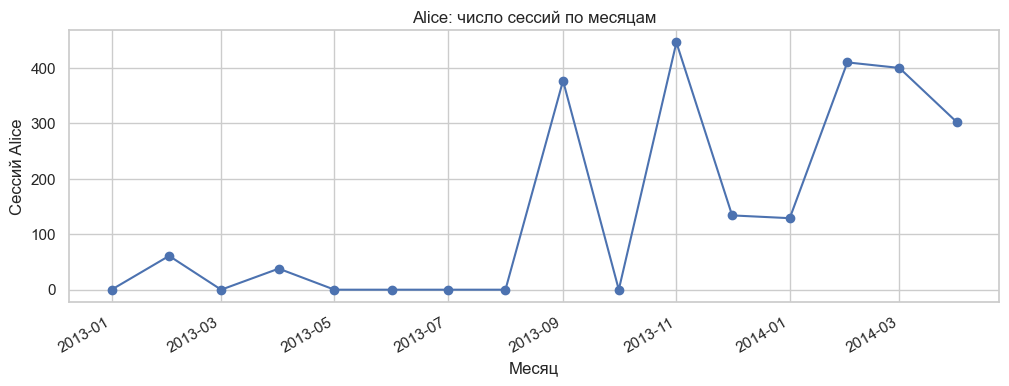

In [43]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(alice_monthly.index.to_timestamp(), alice_monthly.to_numpy(), marker='o')
ax.set(title='Alice: число сессий по месяцам', xlabel='Месяц', ylabel='Сессий Alice')
fig.autofmt_xdate()
save_show(fig, '06_alice_monthly.png')

Одна точка — один календарный месяц. Рисунок показывает изменение количества сессий, а не активности внутри одной сессии. Проверяем общий тренд в доступной части запрошенного периода — с января 2013 по апрель 2014; наличие колебаний отдельно проверяем по помесячным разностям.

Проверяем снижение, постоянство и рост количества сессий.

In [44]:
slope = np.polyfit(np.arange(len(trend_counts)), trend_counts.to_numpy(), 1)[0]
print('Доступная часть периода: январь 2013 —', known_end)
print(f'Наклон общего тренда: {slope:.2f} сессии в месяц')
print('Тренд доступной части периода направлен вниз:', slope < 0)
print('Количество строго одинаково за весь период:', alice_monthly.nunique() == 1)
print('Тренд доступной части периода направлен вверх:', slope > 0)
print('Строго уменьшается каждый месяц:', (trend_counts.diff().dropna() < 0).all())
print('Строго увеличивается каждый месяц:', (trend_counts.diff().dropna() > 0).all())

Доступная часть периода: январь 2013 — 2014-04
Наклон общего тренда: 26.19 сессии в месяц
Тренд доступной части периода направлен вниз: False
Количество строго одинаково за весь период: False
Тренд доступной части периода направлен вверх: True
Строго уменьшается каждый месяц: False
Строго увеличивается каждый месяц: False


Общий тренд и изменение каждый месяц — разные утверждения. Наклон позволяет оценить общее направление, но не доказывает постоянное уменьшение или увеличение. По графику и помесячным разностям видно, сохраняется ли это направление на каждом шаге.

### 5.5. Какие методы линейные и что такое гиперпараметры?
Логистическая регрессия, персептрон и линейный SVM используют взвешенную сумму признаков. Веса и свободный член обучаются по данным. Гиперпараметры задают способ обучения: например, C, вид регуляризации, метод решения и число итераций. C в этой работе подбирался по проверке.

### 5.6. Для чего нужен стохастический градиент?
Метод постепенно обновляет веса, используя один объект или небольшую порцию данных на каждом шаге. Так можно обучать модель на больших наборах, не пересчитывая всю таблицу для одного обновления. Размер шага влияет на скорость и устойчивость обучения. В выполненном примере использован решатель `liblinear`, а не самостоятельно реализованный стохастический градиент.

### 5.7. Что такое линейно разделимая выборка?
Это данные, классы которых можно без ошибок разделить прямой, плоскостью или соответствующей линейной границей при большем числе признаков. Не каждый настоящий набор имеет такое разделение.
